In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 01 — The data, and how we measure a preference (2026-11-02)

**GRUMish series** (laptops only, no new runs): 00 README · **01 data and weights** · 02 one requirement ·
03 brand contracts · 04 two and three requirements · 05 what the base model can predict · 06 how many samples.

This notebook sets up the two objects every later notebook uses:
1. **which runs exist** (which model got which contract);
2. **the weights** — how much the model likes each level of each feature, measured in a way that is fair to the
   lexicographic models (RAM first, then the rest).

In [2]:
from grumish import *
import matplotlib.pyplot as plt
setup_plots()
FIG = "figs/GRUMish"; os.makedirs(FIG, exist_ok=True)
R = load_all()
print(len(R), "runs (frame `shopping`, complete, 9900 rows each)")

96 runs (frame `shopping`, complete, 9900 rows each)


## 1. Which runs exist

A **contract** is the sentence in the prompt, like *"I prefer 8 GB ram and a 14-inch screen."*. It names 0, 1, 2 or
3 features. Every run = one model × one contract, all 45 laptops, all 990 pairs in both orders, 5 templates.

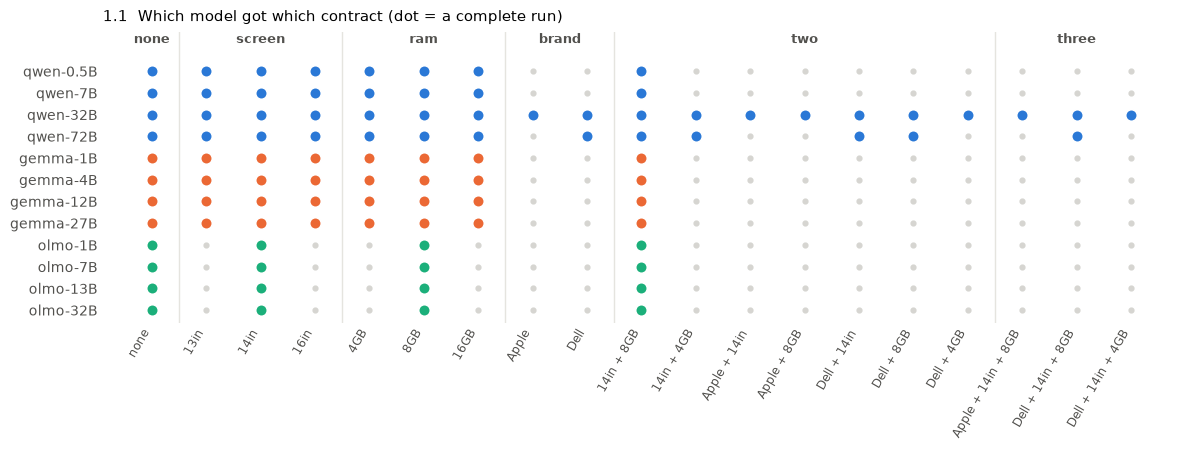

{'none': 12, 'screen': 28, 'ram': 28, 'brand': 3, 'two': 21, 'three': 4}


In [3]:
GROUPS = [("none", ["none"]),
          ("screen", ["screen=13-inch", "screen=14-inch", "screen=16-inch"]),
          ("ram", ["ram=4GB", "ram=8GB", "ram=16GB"]),
          ("brand", ["brand=Apple", "brand=Dell"]),
          ("two", ["ram=8GB+screen=14-inch", "ram=4GB+screen=14-inch", "brand=Apple+screen=14-inch", "brand=Apple+ram=8GB",
                   "brand=Dell+screen=14-inch", "brand=Dell+ram=8GB", "brand=Dell+ram=4GB"]),
          ("three", ["brand=Apple+ram=8GB+screen=14-inch", "brand=Dell+ram=8GB+screen=14-inch", "brand=Dell+ram=4GB+screen=14-inch"])]
CONS = [c for _, cs in GROUPS for c in cs]
fig, ax = plt.subplots(figsize=(12, 4.6))
for j, c in enumerate(CONS):
    for i, m in enumerate(MODELS):
        if (m, c) in R:
            ax.scatter(j, i, s=70, color=FAMC[FAMILY[m]], edgecolor="white", linewidth=1.2, zorder=3)
        else:
            ax.scatter(j, i, s=12, color=LGRAY, zorder=2)
x0 = 0
for g, cs in GROUPS:
    ax.text(x0 + (len(cs) - 1) / 2, -1.3, g, ha="center", fontsize=9.5, fontweight="bold", color=INK2)
    if x0: ax.axvline(x0 - 0.5, color=GRID, lw=1)
    x0 += len(cs)
ax.set_xticks(range(len(CONS)), [short(c) for c in CONS], rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(MODELS)), MODELS); ax.set_ylim(len(MODELS) - 0.4, -1.8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("1.1  Which model got which contract (dot = a complete run)", loc="left", pad=8)
fig.tight_layout(); fig.savefig(f"{FIG}/01_1_coverage.png", dpi=150); plt.show()
print({g: sum((m, c) in R for c in cs for m in MODELS) for g, cs in GROUPS})

- **96 complete runs.** The 8 qwen and gemma models have **all 6 one-requirement spec contracts** (13/14/16-inch,
  4/8/16GB). OLMo has only `14-inch` and `8GB`.
- **Brand contracts and almost all two- and three-requirement contracts exist only for qwen-32B (19 contracts) and
  qwen-72B (13).** Only 4 three-requirement runs exist.
- So: questions about **levels** can use 7 models (qwen-0.5B is noise); questions about **brand and compounds** are
  mostly about qwen-32B and qwen-72B. Every result in notebooks 03–04 carries that limit.

## 2. How we measure: the position-corrected margin D, and ceteris-paribus weights

**D.** For two laptops x and y the model gives a margin m(x, y) = log-prob("1") − log-prob("2") when x is option 1.
We ask both orders and average: **D(x, y) = (m(x, y) − m(y, x)) / 2**. The pull toward option 1 or 2 (positional
bias) cancels, and so does the PMI constant of the old runs. Nothing below needs γ.

**Weights.** We want one number per level: "how much does the model like 16 GB, 8 GB, 4 GB?". Two ways:
- **all-pairs** (what `FeatureBT` does): fit *u(laptop) = w(brand) + w(screen) + w(ram)* on all 990 pairs.
- **ceteris paribus (CP)**: measure each feature **only on pairs that differ in that feature alone**. Brand from
  "Apple 14in 8GB vs Dell 14in 8GB" (90 pairs), screen from pairs with the same brand and RAM (45), RAM likewise (45).

**We use CP everywhere in this series.** The models are lexicographic: when RAM differs, RAM decides, and brand
does not matter. The all-pairs fit averages brand over those pairs where it is dead, so it shrinks brand by 3–5×
(status.md, point 11). CP measures brand where brand is the only difference — the only place it is defined.
Weights are centred inside each feature (0 = the average level).

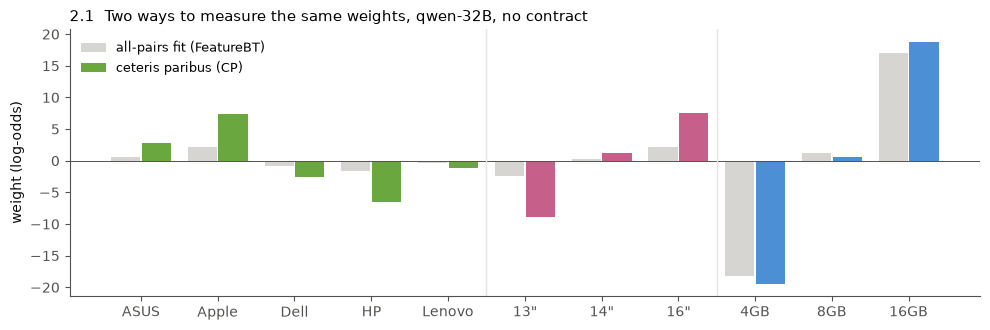

CP range / all-pairs range, no contract:
        qwen-7B  qwen-32B  qwen-72B  gemma-1B  gemma-4B  gemma-12B  gemma-27B  olmo-1B  olmo-7B  olmo-13B  olmo-32B
brand       5.6       3.6       2.8       2.3       3.4        3.2        4.1      1.2      1.4       0.9       1.5
screen      3.4       3.5       2.7       3.0       3.8        3.2        3.4      2.9      2.4       2.8       2.1
ram         1.1       1.1       1.2       1.1       0.9        1.0        1.0      1.4      1.2       1.1       1.2


In [4]:
m = "qwen-32B"
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(LV)); r = R[(m, "none")]
ax.bar(x - 0.2, r.wa.values, 0.38, color=LGRAY, label="all-pairs fit (FeatureBT)")
ax.bar(x + 0.2, r.w.values, 0.38, color=[FEATC[f] for f, _ in LV], label="ceteris paribus (CP)")
ax.axhline(0, color=INK2, lw=0.7)
for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV]); ax.set_ylabel("weight (log-odds)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"2.1  Two ways to measure the same weights, {m}, no contract", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/01_2_cp_vs_allpairs.png", dpi=150); plt.show()
rng = lambda w, f: w[f].max() - w[f].min()
ratio = pd.DataFrame({m: {f: rng(R[(m, "none")].w, f) / rng(R[(m, "none")].wa, f) for f in FEATS} for m in REAL})
print("CP range / all-pairs range, no contract:"); print(ratio.round(1).to_string())

- **RAM is measured the same either way** (CP / all-pairs = 0.9–1.4): RAM decides most pairs anyway.
- **Brand and screen are understated by the all-pairs fit**: CP is 2.3–5.6× bigger for brand and 2.1–3.8× for screen
  in qwen and gemma. In OLMo, whose brand taste is tiny, the two agree (0.9–1.5).
- This is the lexicographic effect: brand matters only when RAM and screen are tied, so it must be measured there.

## 3. The weights of every model with no contract

This is **a** in the GRUM: the model's own taste, the starting point that every contract changes.
Error bar = min–max over the 5 templates (each template is a full design on its own).

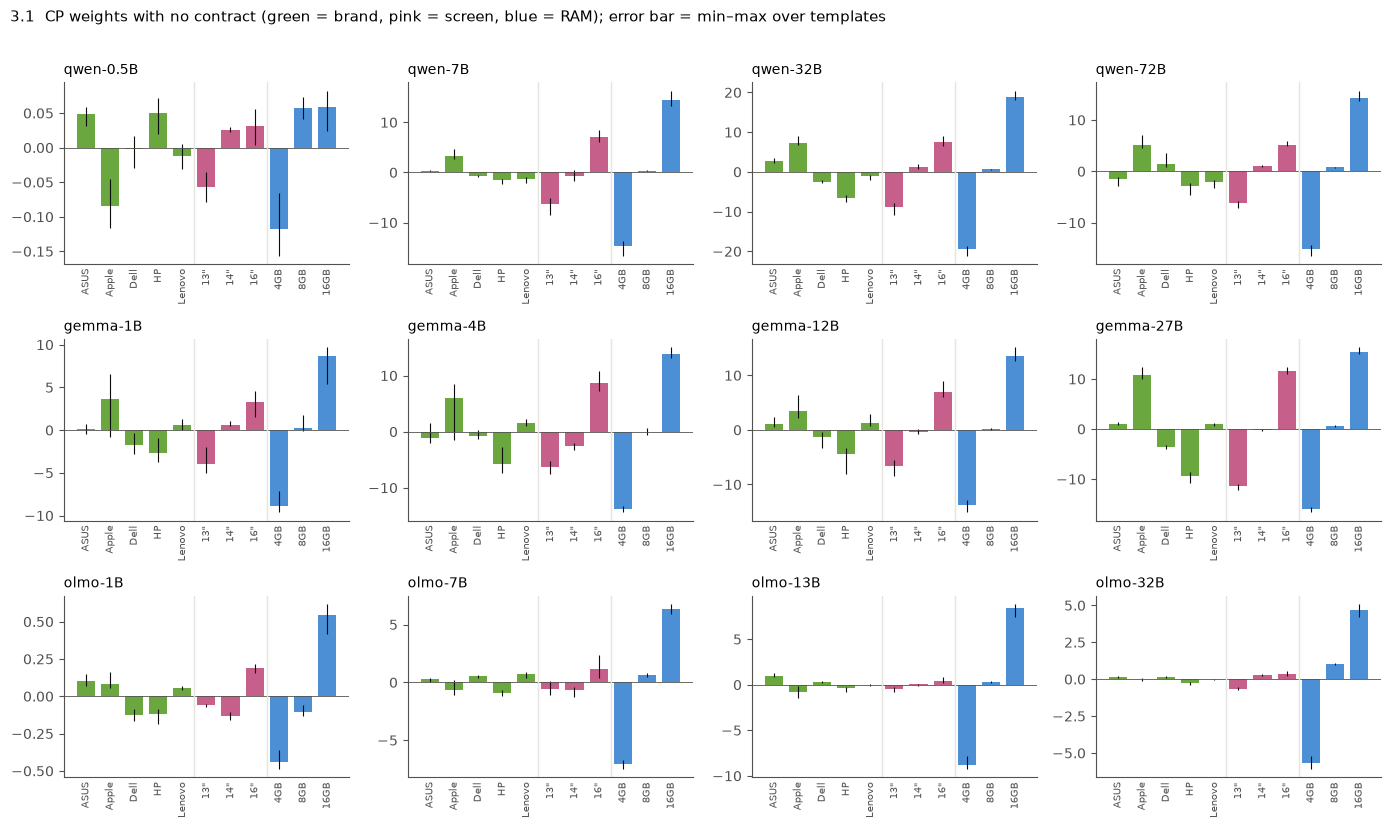

        qwen-0.5B  qwen-7B  qwen-32B  qwen-72B  gemma-1B  gemma-4B  gemma-12B  gemma-27B  olmo-1B  olmo-7B  olmo-13B  olmo-32B
brand         0.1      4.8      13.8       7.9       6.3      11.7        7.8       20.1      0.2      1.6       1.8       0.4
screen        0.1     13.3      16.4      11.4       7.3      14.9       13.5       22.9      0.3      1.8       0.9       1.0
ram           0.2     29.1      38.3      29.4      17.5      27.6       27.2       31.5      1.0     13.4      17.2      10.3


In [5]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8.4))
for ax, m in zip(axes.flat, MODELS):
    r = R[(m, "none")]; mu = r.w.values; x = np.arange(len(LV))
    ax.bar(x, mu, 0.75, color=[FEATC[f] for f, _ in LV])
    ax.errorbar(x, mu, yerr=np.vstack([mu - r.w_t.min(axis=1).values, r.w_t.max(axis=1).values - mu]), fmt="none", ecolor=INK, elinewidth=0.8)
    ax.axhline(0, color=INK2, lw=0.6)
    for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
    ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV], rotation=90, fontsize=7.5); ax.tick_params(axis="x", length=0)
    ax.set_title(m, loc="left", fontsize=10)
fig.suptitle("3.1  CP weights with no contract (green = brand, pink = screen, blue = RAM); error bar = min–max over templates", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(f"{FIG}/01_3_base_weights.png", dpi=150); plt.show()
W0 = pd.DataFrame({m: R[(m, "none")].w for m in MODELS})
print(pd.DataFrame({f: W0.loc[f].max() - W0.loc[f].min() for f in FEATS}).T.round(1).to_string())

- **RAM is the biggest feature in every model** (CP range 10–38 log-odds), then screen and brand.
- **Apple is the top brand in all qwen and gemma models** (+3.2 … +10.8), not in OLMo; HP is at the bottom. 16-inch is
  the favourite screen.
- **The template error bars are small** next to the weights: the 5 templates agree on the taste.
- qwen-0.5B and olmo-1B have a tiny scale (≤ 1 log-odds): treat them as noise floors.

## 4. How far can a "sum of feature weights" go? The ceiling

Every GRUM below predicts **feature weights**, and a laptop's utility = the sum of its 3 weights. So even a perfect
GRUM can only be as good as the best additive description of each run. We measure that ceiling per run:
take the run's **own** CP weights, add them up, and count in how many of the 990 pairs this picks the same winner as
the model did (**pair accuracy**). Later notebooks call this the **oracle**.

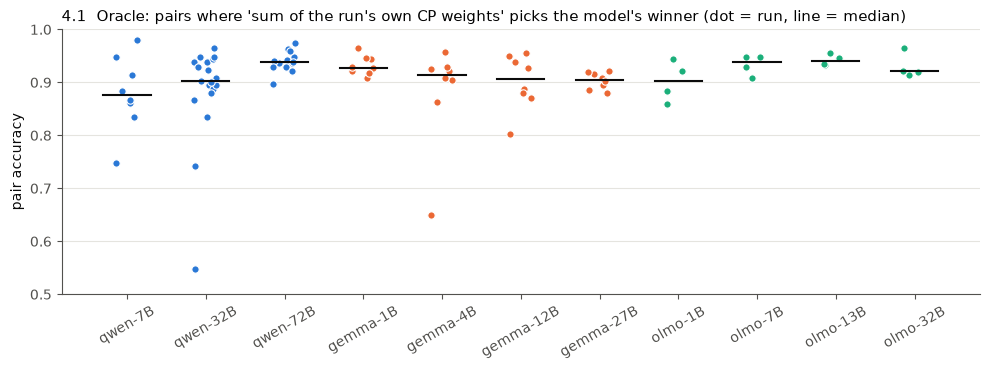

             min  median    max
model                          
qwen-7B    0.748   0.876  0.981
qwen-32B   0.548   0.903  0.966
qwen-72B   0.897   0.939  0.974
gemma-1B   0.909   0.927  0.965
gemma-4B   0.649   0.915  0.958
gemma-12B  0.802   0.907  0.955
gemma-27B  0.880   0.905  0.922
olmo-1B    0.860   0.902  0.944
olmo-7B    0.909   0.939  0.948
olmo-13B   0.933   0.941  0.956
olmo-32B   0.914   0.921  0.966
all runs: {'count': 88.0, 'mean': 0.907, 'std': 0.064, 'min': 0.548, '25%': 0.895, '50%': 0.922, '75%': 0.942, 'max': 0.981}


In [6]:
rows = [dict(model=m, c=c, q=len(parse(c)), acc=pair_accuracy(additive_utility(r.w), r.D)) for (m, c), r in R.items() if m != "qwen-0.5B"]
ACC = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, m in enumerate(REAL):
    s = ACC[ACC.model == m]
    ax.scatter(np.full(len(s), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(s)), s.acc, s=28,
               color=FAMC[FAMILY[m]], edgecolor="white", linewidth=0.8, zorder=3)
    ax.plot([i - 0.3, i + 0.3], [s.acc.median()] * 2, color=INK, lw=1.5, zorder=4)
ax.set_xticks(range(len(REAL)), REAL, rotation=30); ax.set_ylabel("pair accuracy")
ax.set_ylim(0.5, 1.0); ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_title("4.1  Oracle: pairs where 'sum of the run's own CP weights' picks the model's winner (dot = run, line = median)", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/01_4_oracle.png", dpi=150); plt.show()
print(ACC.groupby("model").acc.agg(["min", "median", "max"]).loc[REAL].round(3).to_string())
print("all runs:", ACC.acc.describe().round(3).to_dict())

- **The ceiling is about 0.92 pair accuracy** (median over 88 runs). No feature-weight model can do better than this on
  a run, so later notebooks compare every prediction with it.
- **The hard runs are `ram=4GB`**: qwen-32B 0.55, gemma-4B 0.65, qwen-7B 0.75, gemma-12B 0.80. There the model is torn
  between the request and its strong taste, and no simple sum describes it.
- **The misses are mostly near-ties.** Even one free utility per laptop reaches only 0.94 on average. On the 75% of
  pairs with the clearest D, the CP sum gets 0.96.